# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_: 
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how Euler's method and RK4 work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Iniego, Angel Nicole
- _Student No._: 2024-09622
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

**Figure 1. Lorenz Butterfly** 
<img src="../Figures/013_LorenzButterfly.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 2. Van-der-poll Oscillation.** 
<img src="../Figures/011_VanDerPol.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [42]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

Hint: you may use `euler()` or `rk4()` in Section 3.

In [43]:
def lorenz(t, yvals, sigma, rho, beta):
    x = yvals[0]
    y = yvals[1]
    z = yvals[2]

    dxdt = sigma * (y - x)
    dydt = rho * x - y - x * z
    dzdt = x * y - beta * z

    return np.array([dxdt,dydt,dzdt])

In [44]:
def euler(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit)))  # one column per variable
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

In [45]:
def rk4gen(fs, a, b, n, yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j, x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

In [46]:
def plotting(sigma, rho, beta, a, b, n, yinits):
    # --- attach the parameters so the RHS has the form f(t, yvals) ---
    lorenz_f = lambda t, yvals: lorenz(t, yvals, sigma, rho, beta)

    # --- solve with Euler ---
    ts_euler, ys_euler = euler(lorenz_f, a, b, n, yinits)
    x_euler = ys_euler[:, 0]
    y_euler = ys_euler[:, 1]
    z_euler = ys_euler[:, 2]

    # --- solve with RK4 ---
    ts_rk4, ys_rk4 = rk4gen(lorenz_f, a, b, n, yinits)
    x_rk4 = ys_rk4[:, 0]
    y_rk4 = ys_rk4[:, 1]
    z_rk4 = ys_rk4[:, 2]

    fig = plt.figure(figsize=(14, 6))

    # --- left panel: Euler ---
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    ax1.plot(x_euler, y_euler, z_euler, lw=0.5, color='tab:blue')
    ax1.scatter(yinits[0], yinits[1], yinits[2], color='k', s=20, label='start')
    ax1.set_title('Euler')
    ax1.set_xlabel('x')
    ax1.set_ylabel('y')
    ax1.set_zlabel('z')
    ax1.legend()

    # --- right panel: RK4 ---
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    ax2.plot(x_rk4, y_rk4, z_rk4, lw=0.5, color='tab:red')
    ax2.scatter(yinits[0], yinits[1], yinits[2], color='k', s=20, label='start')
    ax2.set_title('RK4')
    ax2.set_xlabel('x')
    ax2.set_ylabel('y')
    ax2.set_zlabel('z')
    ax2.legend()

    fig.suptitle(rf'Lorenz system: $\sigma$ = {sigma}, $\rho$ = {rho}, '
                 rf'$\beta$ = {beta:.3f},  $t \in$ [{a}, {b}],  n = {n}')
    plt.tight_layout()
    plt.show()

In [47]:
# Setting initial conditions:
a = 0.0
b = 50.0
n = 10000                          # h = 50/9999 ≈ 0.005
yinits = np.array([0.0, 1.0, 0.0]) # (x, y, z) at t = 0

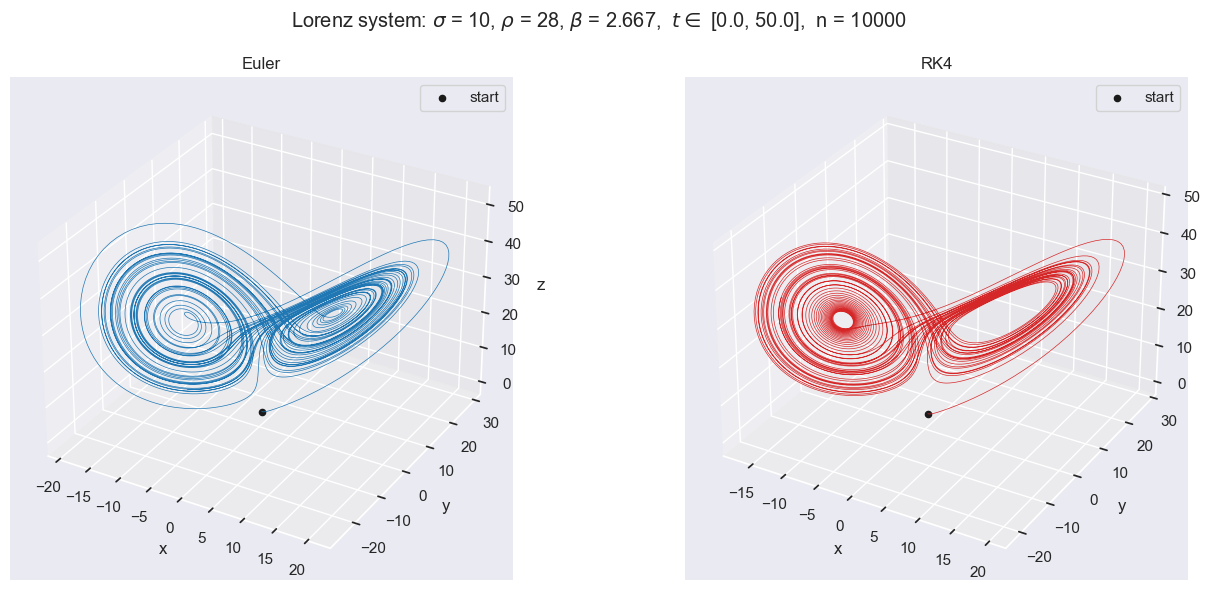

In [48]:
plotting(sigma=10, rho=28, beta=8/3, a=a, b=b, n=n, yinits=yinits)

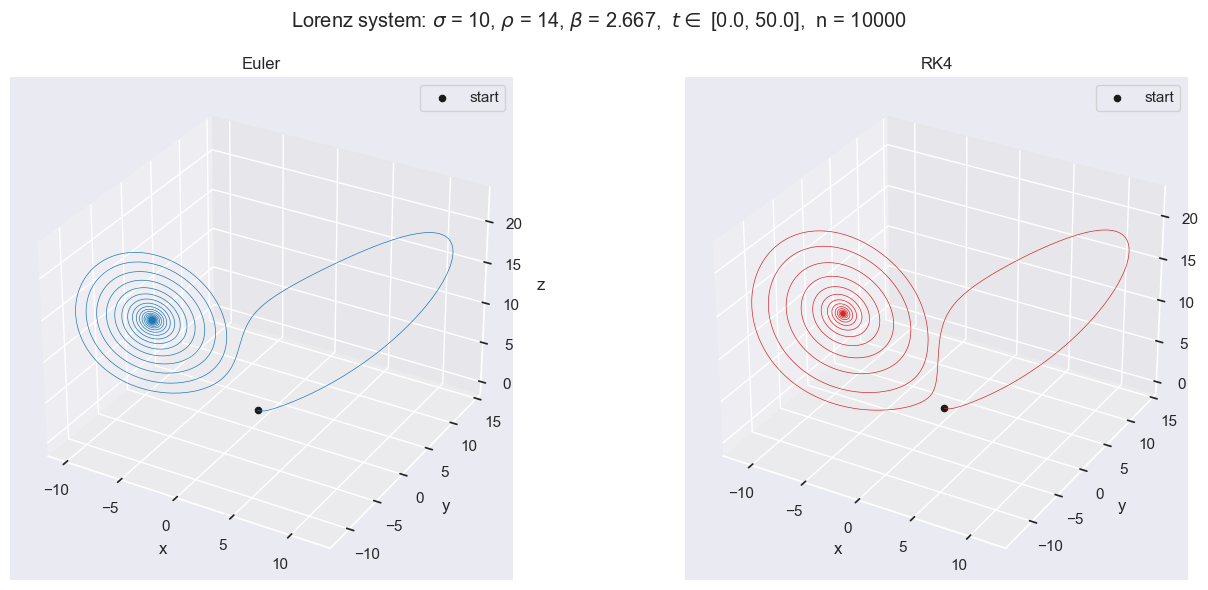

In [49]:
plotting(sigma=10, rho=14, beta=8/3, a=a, b=b, n=n, yinits=yinits)

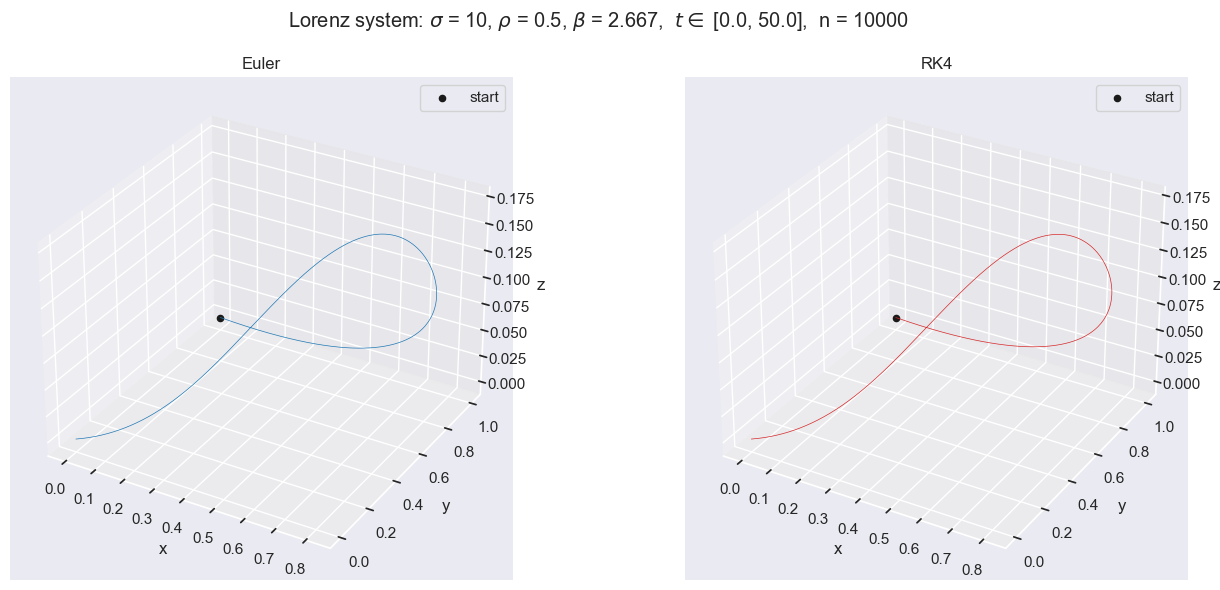

In [50]:
plotting(sigma=10, rho=0.5, beta=8/3, a=a, b=b, n=n, yinits=yinits)

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

In [51]:
def plotting_zx(sigma, rho, beta, a, b, n, yinits):
    # --- attach the parameters so the RHS has the form f(t, yvals) ---
    lorenz_f = lambda t, yvals: lorenz(t, yvals, sigma, rho, beta)

    # --- solve with Euler ---
    ts_euler, ys_euler = euler(lorenz_f, a, b, n, yinits)
    x_euler = ys_euler[:, 0]
    z_euler = ys_euler[:, 2]

    # --- solve with RK4 ---
    ts_rk4, ys_rk4 = rk4gen(lorenz_f, a, b, n, yinits)
    x_rk4 = ys_rk4[:, 0]
    z_rk4 = ys_rk4[:, 2]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # --- left panel: Euler ---
    ax1.plot(x_euler, z_euler, lw=0.5, color='tab:blue')
    ax1.scatter(yinits[0], yinits[2], color='k', s=20, zorder=3, label='start')
    ax1.set_title('Euler')
    ax1.set_xlabel('x')
    ax1.set_ylabel('z')
    ax1.legend()

    # --- right panel: RK4 ---
    ax2.plot(x_rk4, z_rk4, lw=0.5, color='tab:red')
    ax2.scatter(yinits[0], yinits[2], color='k', s=20, zorder=3, label='start')
    ax2.set_title('RK4')
    ax2.set_xlabel('x')
    ax2.set_ylabel('z')
    ax2.legend()

    fig.suptitle(rf'Lorenz strange attractor ($z$ vs $x$): $\sigma$ = {sigma}, $\rho$ = {rho}, '
                 rf'$\beta$ = {beta:.3f},  $t \in$ [{a}, {b}],  n = {n}')
    plt.tight_layout()
    plt.show()

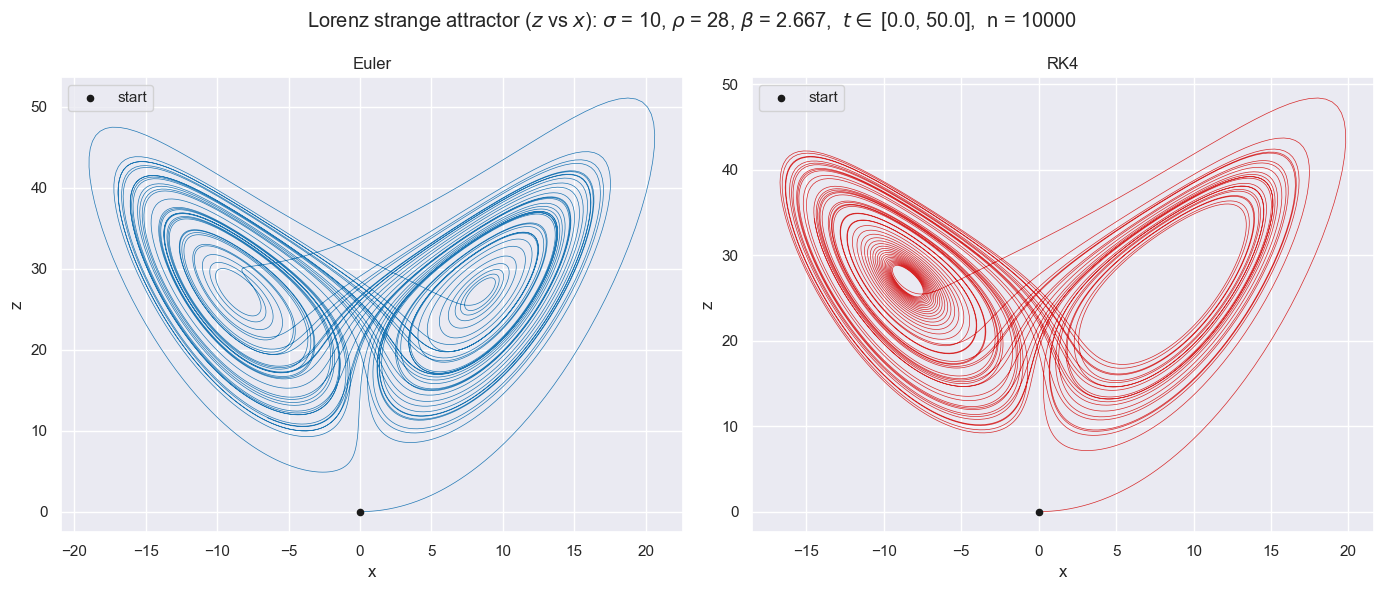

In [52]:
plotting_zx(sigma=10, rho=28, beta=8/3, a=a, b=b, n=n, yinits=yinits)

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

In [53]:
def harmonic(t, yvals, omega):
    x = yvals[0]
    v = yvals[1]

    dxdt = v
    dvdt = -omega**2 * x

    return np.array([dxdt, dvdt])


def anharmonic(t, yvals, omega):
    x = yvals[0]
    v = yvals[1]

    dxdt = v
    dvdt = -omega**2 * x**3

    return np.array([dxdt, dvdt])


def vanderpol(t, yvals, omega, mu):
    x = yvals[0]
    v = yvals[1]

    dxdt = v
    dvdt = mu * (1 - x**2) * v - omega**2 * x

    return np.array([dxdt, dvdt])

In [54]:
def period(ts, xs):
    # indices j where x goes from negative (j) to non-negative (j+1)
    up = np.where((xs[:-1] < 0) & (xs[1:] >= 0))[0]

    # linear interpolation for the crossing time between ts[j] and ts[j+1]
    t_cross = ts[up] - xs[up] * (ts[up + 1] - ts[up]) / (xs[up + 1] - xs[up])

    # average time between consecutive upward crossings
    return np.mean(np.diff(t_cross))

In [55]:
def plotting_xt(f, a, b, n, yinits, title):
    # --- solve with Euler ---
    ts_euler, ys_euler = euler(f, a, b, n, yinits)
    x_euler = ys_euler[:, 0]

    # --- solve with RK4 ---
    ts_rk4, ys_rk4 = rk4gen(f, a, b, n, yinits)
    x_rk4 = ys_rk4[:, 0]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

    # --- left panel: Euler ---
    ax1.plot(ts_euler, x_euler, lw=1, color='tab:blue')
    ax1.set_title('Euler')
    ax1.set_xlabel('t')
    ax1.set_ylabel('x(t)')

    # --- right panel: RK4 ---
    ax2.plot(ts_rk4, x_rk4, lw=1, color='tab:red')
    ax2.set_title('RK4')
    ax2.set_xlabel('t')
    ax2.set_ylabel('x(t)')

    fig.suptitle(title + rf',  $x_0$ = {yinits[0]}, $v_0$ = {yinits[1]},  n = {n}')
    plt.tight_layout()
    plt.show()

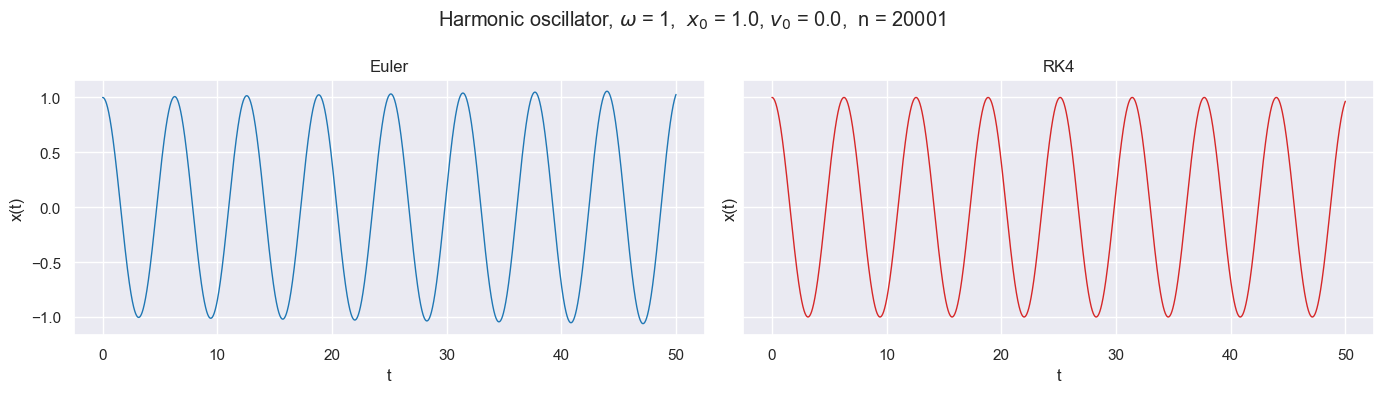

In [56]:
omega = 1.0
a = 0.0
b = 50.0
n = 20001                           # h = 50/20000 = 0.0025
yinits = np.array([1.0, 0.0])       # (x, dx/dt) at t = 0

harmonic_f = lambda t, yvals: harmonic(t, yvals, omega)

plotting_xt(harmonic_f, a, b, n, yinits, title=r'Harmonic oscillator, $\omega$ = 1')

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

In [57]:
def plotting_xt_amp(f, a, b, n, yinits_1, yinits_2, title):
    # --- solve amplitude 1 ---
    ts_euler_1, ys_euler_1 = euler(f, a, b, n, yinits_1)
    ts_rk4_1, ys_rk4_1 = rk4gen(f, a, b, n, yinits_1)

    # --- solve amplitude 2 ---
    ts_euler_2, ys_euler_2 = euler(f, a, b, n, yinits_2)
    ts_rk4_2, ys_rk4_2 = rk4gen(f, a, b, n, yinits_2)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

    # --- left panel: Euler ---
    ax1.plot(ts_euler_1, ys_euler_1[:, 0], lw=1, label=rf'$x_0$ = {yinits_1[0]}')
    ax1.plot(ts_euler_2, ys_euler_2[:, 0], lw=1, label=rf'$x_0$ = {yinits_2[0]}')
    ax1.set_title('Euler')
    ax1.set_xlabel('t')
    ax1.set_ylabel('x(t)')
    ax1.legend(loc='upper right')

    # --- right panel: RK4 ---
    ax2.plot(ts_rk4_1, ys_rk4_1[:, 0], lw=1, label=rf'$x_0$ = {yinits_1[0]}')
    ax2.plot(ts_rk4_2, ys_rk4_2[:, 0], lw=1, label=rf'$x_0$ = {yinits_2[0]}')
    ax2.set_title('RK4')
    ax2.set_xlabel('t')
    ax2.set_ylabel('x(t)')
    ax2.legend(loc='upper right')

    fig.suptitle(title + rf',  n = {n}')
    plt.tight_layout()
    plt.show()

    # --- period check (RK4) ---
    T_1 = period(ts_rk4_1, ys_rk4_1[:, 0])
    T_2 = period(ts_rk4_2, ys_rk4_2[:, 0])
    print(f'RK4 period for x0 = {yinits_1[0]}: T = {T_1:.4f}')
    print(f'RK4 period for x0 = {yinits_2[0]}: T = {T_2:.4f}')

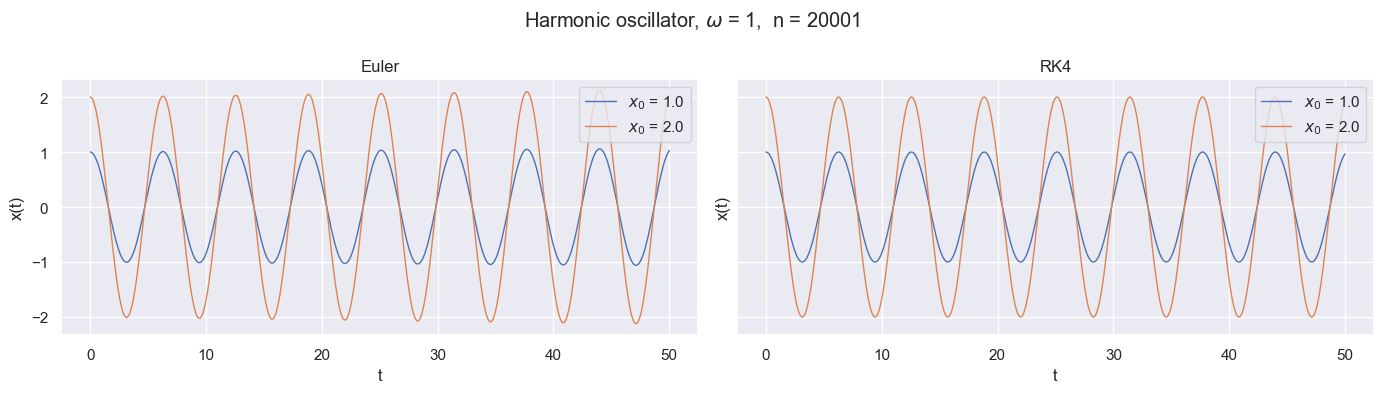

RK4 period for x0 = 1.0: T = 6.2832
RK4 period for x0 = 2.0: T = 6.2832


In [58]:
yinits_1 = np.array([1.0, 0.0])
yinits_2 = np.array([2.0, 0.0])

plotting_xt_amp(harmonic_f, a, b, n, yinits_1, yinits_2,
                title=r'Harmonic oscillator, $\omega$ = 1')

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

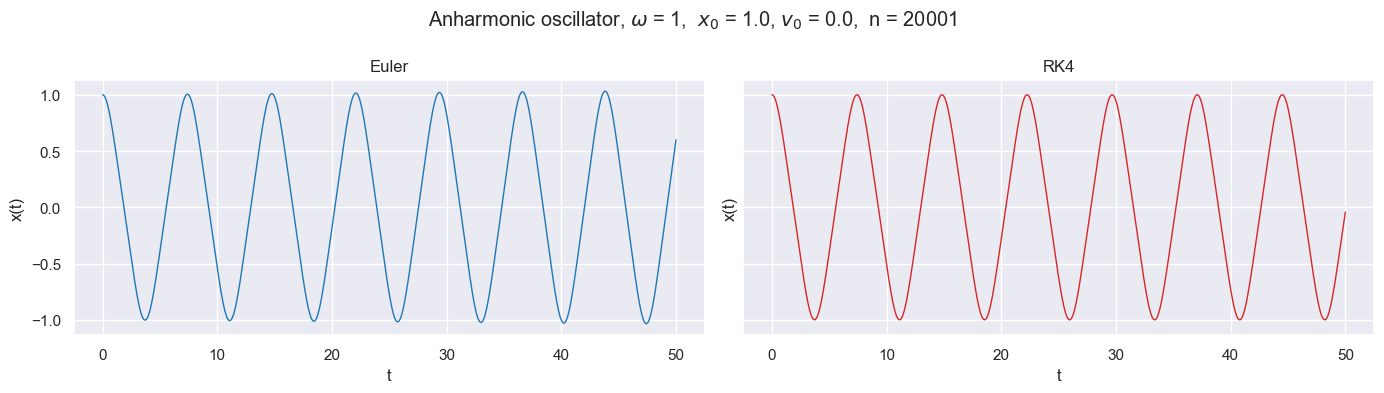

In [59]:
anharmonic_f = lambda t, yvals: anharmonic(t, yvals, omega)

plotting_xt(anharmonic_f, a, b, n, yinits, title=r'Anharmonic oscillator, $\omega$ = 1')

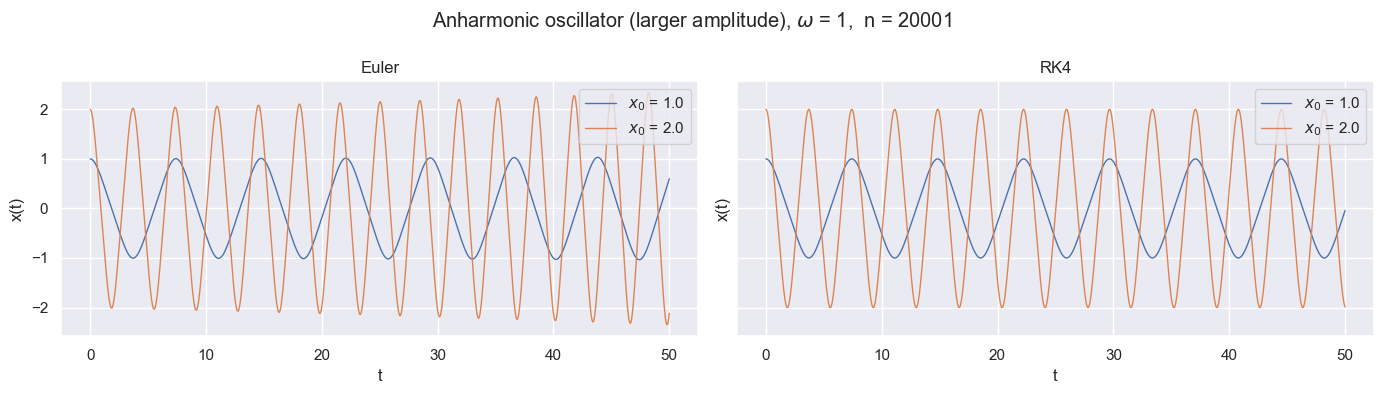

RK4 period for x0 = 1.0: T = 7.4163
RK4 period for x0 = 2.0: T = 3.7081


In [60]:
yinits_1 = np.array([1.0, 0.0])
yinits_2 = np.array([2.0, 0.0])

plotting_xt_amp(anharmonic_f, a, b, n, yinits_1, yinits_2,
                title=r'Anharmonic oscillator (larger amplitude), $\omega$ = 1')

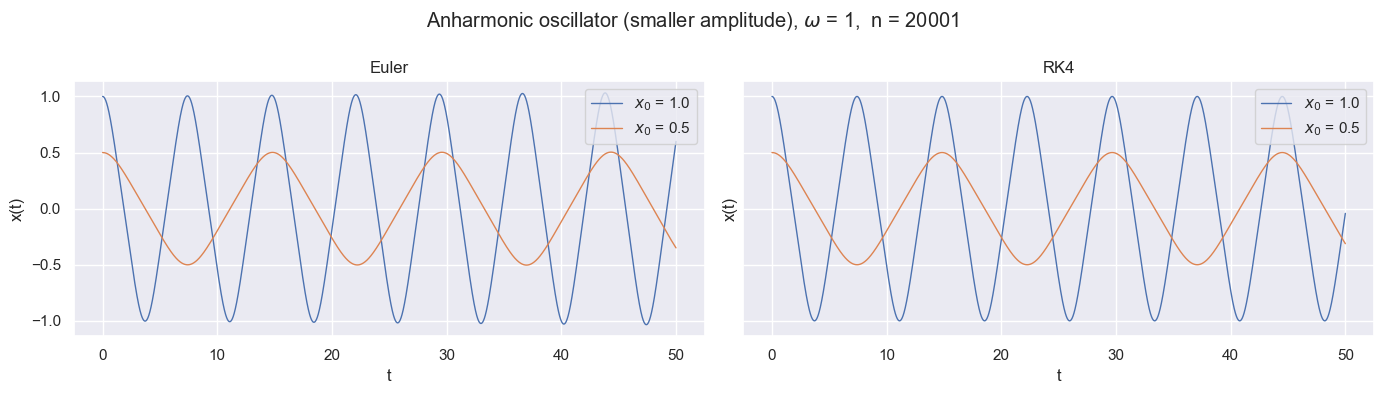

RK4 period for x0 = 1.0: T = 7.4163
RK4 period for x0 = 0.5: T = 14.8326


In [61]:
yinits_1 = np.array([1.0, 0.0])
yinits_2 = np.array([0.5, 0.0])

plotting_xt_amp(anharmonic_f, a, b, n, yinits_1, yinits_2,
                title=r'Anharmonic oscillator (smaller amplitude), $\omega$ = 1')

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

In [62]:
def plotting_phase(f, a, b, n, yinits_1, yinits_2, title):
    # --- solve amplitude 1 ---
    ts_euler_1, ys_euler_1 = euler(f, a, b, n, yinits_1)
    ts_rk4_1, ys_rk4_1 = rk4gen(f, a, b, n, yinits_1)

    # --- solve amplitude 2 ---
    ts_euler_2, ys_euler_2 = euler(f, a, b, n, yinits_2)
    ts_rk4_2, ys_rk4_2 = rk4gen(f, a, b, n, yinits_2)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

    # --- left panel: Euler ---
    ax1.plot(ys_euler_1[:, 0], ys_euler_1[:, 1], lw=1, label=rf'$x_0$ = {yinits_1[0]}')
    ax1.plot(ys_euler_2[:, 0], ys_euler_2[:, 1], lw=1, label=rf'$x_0$ = {yinits_2[0]}')
    ax1.set_title('Euler')
    ax1.set_xlabel('x')
    ax1.set_ylabel('dx/dt')
    ax1.legend(loc='upper right')

    # --- right panel: RK4 ---
    ax2.plot(ys_rk4_1[:, 0], ys_rk4_1[:, 1], lw=1, label=rf'$x_0$ = {yinits_1[0]}')
    ax2.plot(ys_rk4_2[:, 0], ys_rk4_2[:, 1], lw=1, label=rf'$x_0$ = {yinits_2[0]}')
    ax2.set_title('RK4')
    ax2.set_xlabel('x')
    ax2.set_ylabel('dx/dt')
    ax2.legend(loc='upper right')

    fig.suptitle(title + rf',  n = {n}')
    plt.tight_layout()
    plt.show()

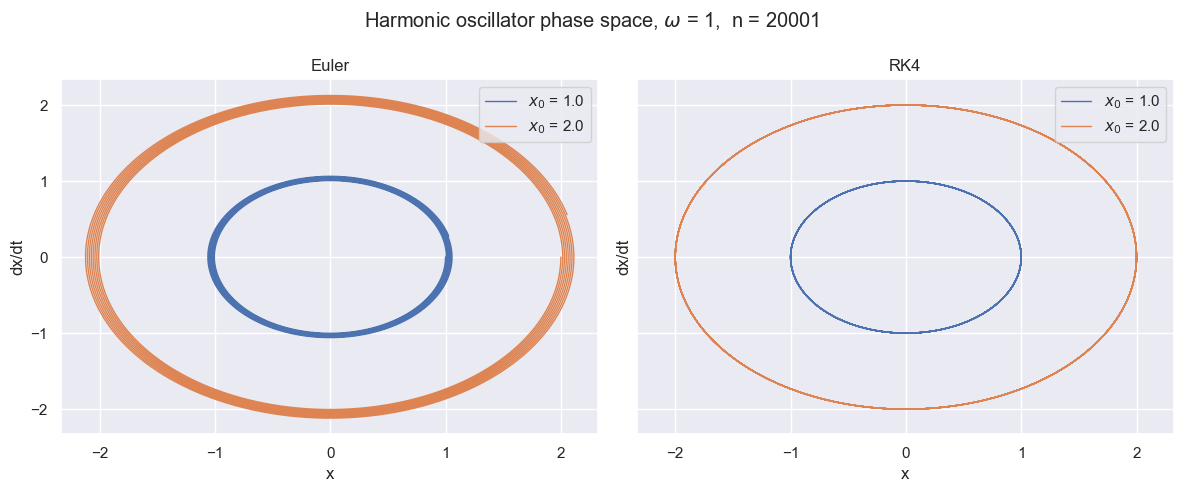

In [63]:
yinits_1 = np.array([1.0, 0.0])
yinits_2 = np.array([2.0, 0.0])

plotting_phase(harmonic_f, a, b, n, yinits_1, yinits_2,
               title=r'Harmonic oscillator phase space, $\omega$ = 1')

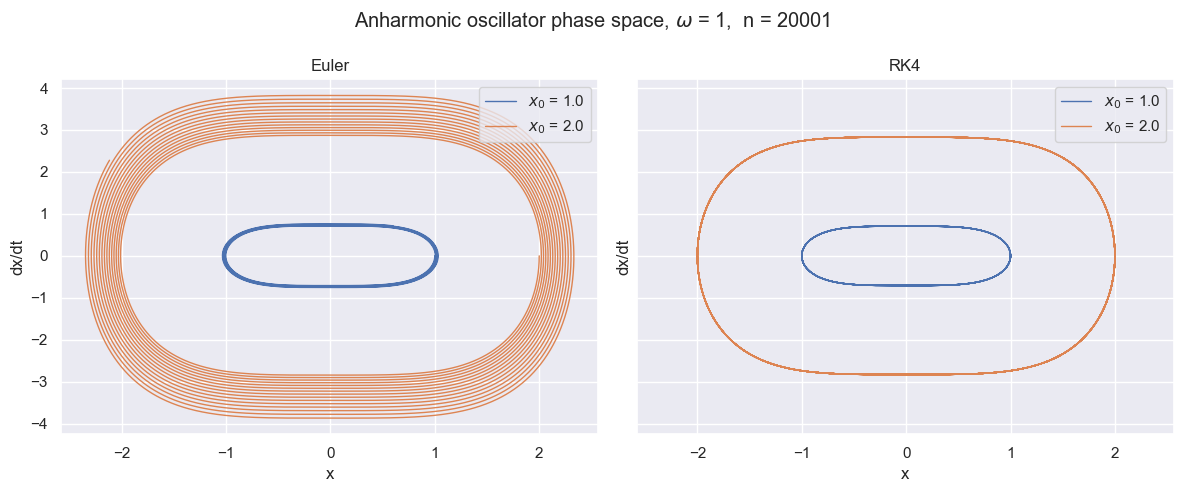

In [64]:
plotting_phase(anharmonic_f, a, b, n, yinits_1, yinits_2,
               title=r'Anharmonic oscillator phase space, $\omega$ = 1')

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

In [65]:
def plotting_vdp(omega, mu, a, b, n, yinits):
    # --- attach the parameters so the RHS has the form f(t, yvals) ---
    vanderpol_f = lambda t, yvals: vanderpol(t, yvals, omega, mu)

    # --- solve with Euler ---
    ts_euler, ys_euler = euler(vanderpol_f, a, b, n, yinits)
    x_euler = ys_euler[:, 0]
    v_euler = ys_euler[:, 1]

    # --- solve with RK4 ---
    ts_rk4, ys_rk4 = rk4gen(vanderpol_f, a, b, n, yinits)
    x_rk4 = ys_rk4[:, 0]
    v_rk4 = ys_rk4[:, 1]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

    # --- left panel: Euler ---
    ax1.plot(x_euler, v_euler, lw=1, color='tab:blue')
    ax1.scatter(yinits[0], yinits[1], color='k', s=20, zorder=3, label='start')
    ax1.set_title('Euler')
    ax1.set_xlabel('x')
    ax1.set_ylabel('dx/dt')
    ax1.legend(loc='upper right')

    # --- right panel: RK4 ---
    ax2.plot(x_rk4, v_rk4, lw=1, color='tab:red')
    ax2.scatter(yinits[0], yinits[1], color='k', s=20, zorder=3, label='start')
    ax2.set_title('RK4')
    ax2.set_xlabel('x')
    ax2.set_ylabel('dx/dt')
    ax2.legend(loc='upper right')

    fig.suptitle(rf'Van der Pol phase space: $\omega$ = {omega}, $\mu$ = {mu},  '
                 rf'$t \in$ [{a}, {b}],  n = {n}')
    plt.tight_layout()
    plt.show()

In [66]:
omega = 1.0
a = 0.0
b = 20.0
n = 4001                            # h = 20/4000 = 0.005
yinits = np.array([1.0, 0.0])       # (x, dx/dt) at t = 0

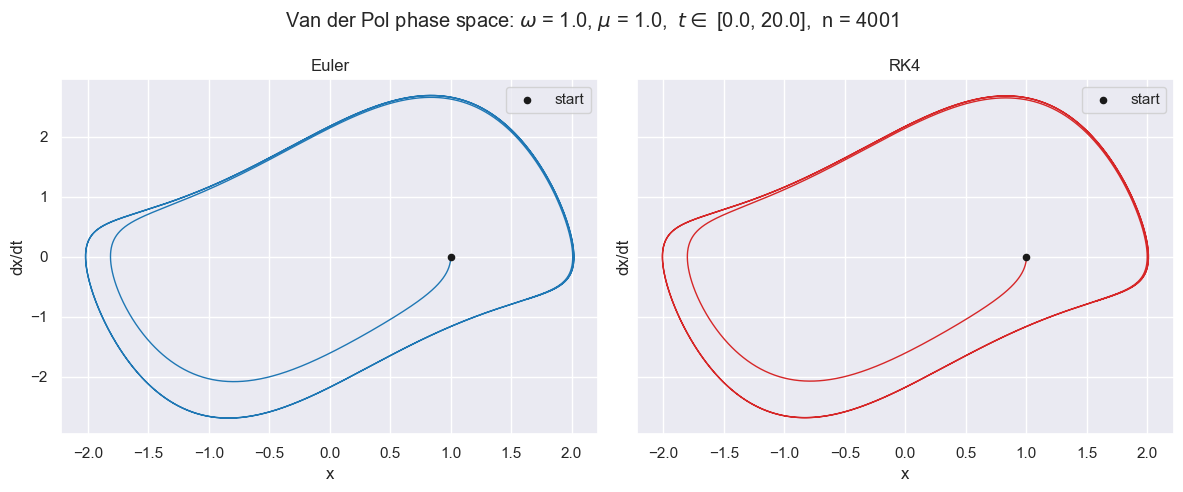

In [67]:
plotting_vdp(omega=1.0, mu=1.0, a=a, b=b, n=n, yinits=yinits)

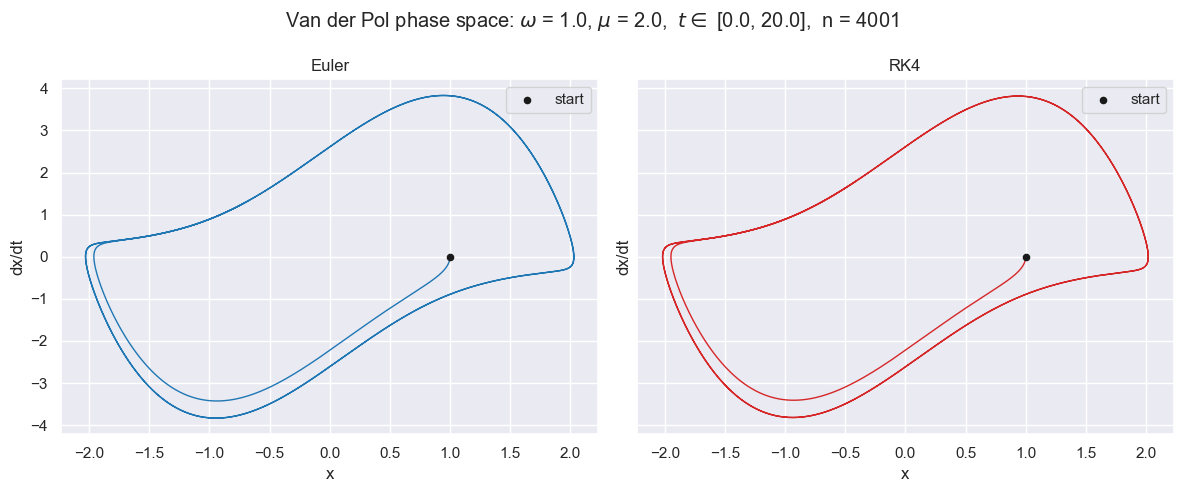

In [68]:
plotting_vdp(omega=1.0, mu=2.0, a=a, b=b, n=n, yinits=yinits)

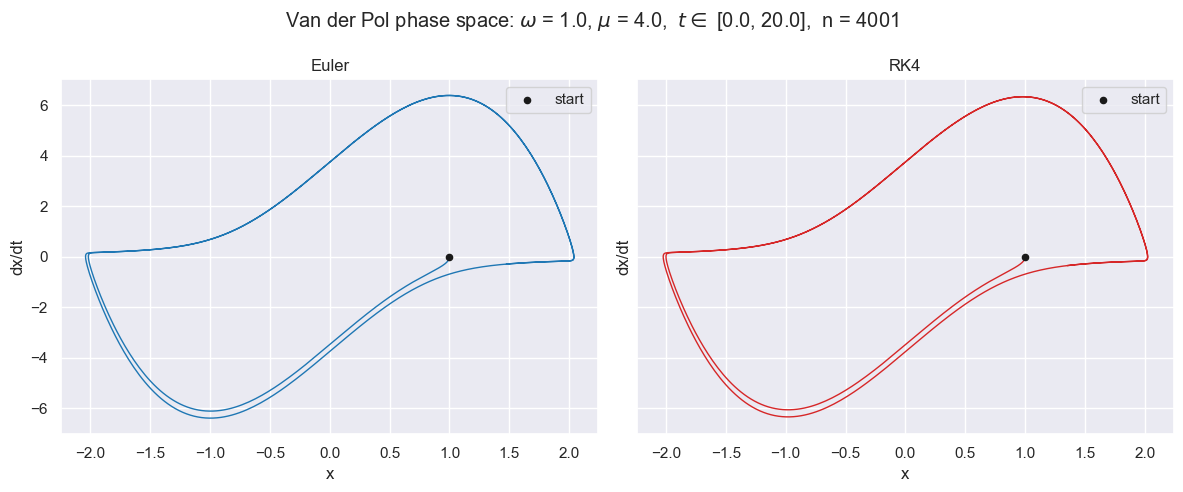

In [69]:
plotting_vdp(omega=1.0, mu=4.0, a=a, b=b, n=n, yinits=yinits)

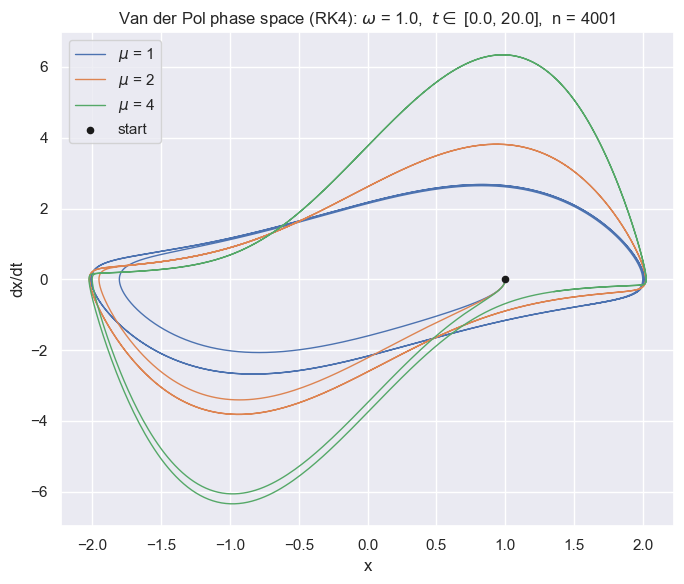

In [70]:
def plotting_vdp_mus(omega, a, b, n, yinits):
    vanderpol_f_1 = lambda t, yvals: vanderpol(t, yvals, omega, 1.0)
    vanderpol_f_2 = lambda t, yvals: vanderpol(t, yvals, omega, 2.0)
    vanderpol_f_4 = lambda t, yvals: vanderpol(t, yvals, omega, 4.0)

    ts_1, ys_1 = rk4gen(vanderpol_f_1, a, b, n, yinits)
    ts_2, ys_2 = rk4gen(vanderpol_f_2, a, b, n, yinits)
    ts_4, ys_4 = rk4gen(vanderpol_f_4, a, b, n, yinits)

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(ys_1[:, 0], ys_1[:, 1], lw=1, label=r'$\mu$ = 1')
    ax.plot(ys_2[:, 0], ys_2[:, 1], lw=1, label=r'$\mu$ = 2')
    ax.plot(ys_4[:, 0], ys_4[:, 1], lw=1, label=r'$\mu$ = 4')
    ax.scatter(yinits[0], yinits[1], color='k', s=20, zorder=3, label='start')
    ax.set_xlabel('x')
    ax.set_ylabel('dx/dt')
    ax.set_title(rf'Van der Pol phase space (RK4): $\omega$ = {omega},  '
                 rf'$t \in$ [{a}, {b}],  n = {n}')
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

plotting_vdp_mus(omega=1.0, a=a, b=b, n=n, yinits=yinits)

#### Problem code summary

The code is broken into components, which carries the principle from the first: defining the functions, solving using Euler and rk4, and then the plotting functions.

---
## Section 3: Notes

In [71]:
import numpy as np

# Ricatti equation (mildly nonlinear)
def f(x,y):
    return - (30/(1-x**2)) + ((2*x)/(1-x**2))*y - y**2

### IVPs

#### 1st order ODE solver: Euler's method

In [72]:
# forward Euler's method
def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

#### 1st order ODE solver: Rungke-Kutta method

In [73]:
# 4th order Runge-Kutta method
def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

In [74]:
# execution
a, b, n, yinit = 0.05, 0.49, 12, 19.53
xs, ys = euler(f,a,b,n,yinit); print(ys)
xs, ys = rk4(f,a,b,n,yinit); print(ys)

[ 19.53         3.14847227   1.56501191   0.26296871  -0.97182666
  -2.28204589  -3.81903888  -5.80936521  -8.6780744  -13.37838499
 -22.50759395 -45.29198435]
[ 19.53        10.16782416   6.37032643   4.11921483   2.48829431
   1.12081032  -0.17770512  -1.56533384  -3.24322678  -5.58940124
  -9.6041146  -19.50349262]


#### 2nd-order ODE: RK4

In [75]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])
    
def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [76]:
import numpy as np
import matplotlib.pyplot as plt

# Updated to handle arrays (systems of ODEs)
def euler(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

def rk4(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

#### Shooting methods

In [77]:
def secant(f,x0,x1,kmax=200,tol=1.e-8):
    f0 = f(x0)
    for k in range(1,kmax):
        f1 = f(x1)
        ratio = (x1 - x0)/(f1 - f0)
        x2 = x1 - f1*ratio
        xdiff = abs(x2-x1)
        x0, x1 = x1, x2
        f0 = f1
        rowf = "{0:2d}{1:1.16f} {2:1.16f} {3:1.16f}"
        print(rowf.format(k,x2,xdiff,abs(f(x2))))
        if abs(xdiff/x2) < tol:
            break
    else:
        x2 = None
    
    return x2

def shoot(sig):
    a, b, n = 0.05, 0.49, 100
    yinits = np.array([0.0926587109375, sig])
    xs, ys = rk4gen(fs,a,b,n,yinits)
    wfinal = 0.11177050858750004
    return ys[-1, 0] - wfinal

wder = secant(shoot,0.,1.)
print(wder)

 11.8096210699240751 0.8096210699240751 0.0000000000000001
 21.8096210699240738 0.0000000000000013 0.0000000000000001
1.8096210699240738


#### BVP matrix

In [78]:
import numpy as np

# Gaussian elimination with partial pivoting (gauelimpivot.py is not in this folder, so it is defined here)
def backsub(U,bs):
    n = bs.size
    xs = np.zeros(n)
    xs[n-1] = bs[n-1]/U[n-1,n-1]
    for i in range(n-2,-1,-1):
        xs[i] = (bs[i] - U[i,i+1:]@xs[i+1:])/U[i,i]
    return xs

def gauelimpivot(inA,inbs):
    A = np.copy(inA)
    bs = np.copy(inbs)
    n = bs.size
    for j in range(n-1):
        k = np.argmax(np.abs(A[j:,j])) + j
        if k != j:
            A[[j,k],:] = A[[k,j],:]
            bs[[j,k]] = bs[[k,j]]
        for i in range(j+1,n):
            coeff = A[i,j]/A[j,j]
            A[i,j:] -= coeff*A[j,j:]
            bs[i] -= coeff*bs[j]
    return backsub(A,bs)

def matsetup(a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    A = np.zeros((n,n))
    np.fill_diagonal(A, -2 + 30*h**2/(1-xs**2))
    A[0,0] = 1; A[-1,-1] = 1
    np.fill_diagonal(A[1:,:], 1 + h*xs[1:]/(1-xs[1:]**2))
    A[-1,-2] = 0
    np.fill_diagonal(A[:,1:], 1 - h*xs/(1-xs**2))
    A[0,1] = 0
    bs = np.zeros(n)
    bs[0] = 0.0926587109375
    bs[-1] = 0.11177050858750004
    return A, bs

def riccati(a,b,n):
    A, bs = matsetup(a, b, n)
    ws = gauelimpivot(A, bs)
    return ws

a, b, n = 0.05, 0.49, 400
ws = riccati(a, b, n); print(ws)

[0.09265871 0.0946527  0.09664346 0.0986309  0.10061498 0.10259561
 0.10457273 0.10654627 0.10851616 0.11048233 0.11244472 0.11440326
 0.11635788 0.1183085  0.12025507 0.12219752 0.12413578 0.12606977
 0.12799944 0.12992472 0.13184553 0.13376182 0.13567351 0.13758053
 0.13948283 0.14138033 0.14327297 0.14516068 0.14704339 0.14892104
 0.15079356 0.15266089 0.15452296 0.1563797  0.15823105 0.16007694
 0.1619173  0.16375208 0.16558121 0.16740462 0.16922224 0.17103401
 0.17283987 0.17463976 0.1764336  0.17822133 0.18000289 0.18177822
 0.18354725 0.18530991 0.18706615 0.1888159  0.1905591  0.19229568
 0.19402558 0.19574873 0.19746509 0.19917457 0.20087713 0.20257269
 0.2042612  0.20594259 0.20761681 0.20928378 0.21094346 0.21259577
 0.21424066 0.21587806 0.21750792 0.21913018 0.22074476 0.22235162
 0.2239507  0.22554192 0.22712525 0.2287006  0.23026793 0.23182718
 0.23337829 0.23492119 0.23645583 0.23798215 0.2395001  0.24100961
 0.24251063 0.2440031  0.24548696 0.24696215 0.24842862 0.2498

#### Shooting method

In [79]:
# secant() is defined in the "Shooting methods" cell above
import numpy as np

def fs(x,yvals,s):
    q = 1.5
    y0, y1 = yvals
    f0 = y1
    f1 = (2*q*np.cos(2*x) - s)*y0
    return np.array([f0, f1])

def rk4geneig(fs,a,b,n,yinits,s):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals,s)
        k1 = h*fs(x+h/2, yvals+k0/2,s)
        k2 = h*fs(x+h/2, yvals+k1/2,s)
        k3 = h*fs(x+h, yvals+k2,s)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys
    
def shoot(s):
    a, b, n = 0, 2*np.pi, 500
    yinits = np.array([0., 5.])
    xs, ys = rk4geneig(fs,a,b,n,yinits,s)
    wfinal = 0.
    return ys[-1, 0] - wfinal

for sinit in (-0.4, 3.3, 8.5):
    sval = secant(shoot,sinit,sinit+0.5)
    print(sval, end=" ")

 1-0.7219890194759320 0.8219890194759319 0.5920168731358919
 2-0.7266488208483880 0.0046598013724560 0.3360641557006793
 3-0.7327671079666472 0.0061182871182592 0.0241617052363766
 4-0.7332410646466375 0.0004739566799903 0.0011641232805274
 5-0.7332650560386976 0.0000239913920601 0.0000044948537985
 6-0.7332651490321059 0.0000000929934083 0.0000000008432683
 7-0.7332651490495554 0.0000000000174495 0.0000000000000129
-0.7332651490495554  13.8184717208946508 0.0184717208946510 0.0281879649988998
 23.8142855326778138 0.0041861882168370 0.0000362865219212
 33.8142909146526160 0.0000053819748023 0.0000000124097890
 43.8142909164938512 0.0000000018412352 0.0000000000000095
3.814290916493851  19.0941293414733586 0.0941293414733586 0.0033667215525718
 29.0926209624857783 0.0015083789875803 0.0000270062652463
 39.0926087651337504 0.0000121973520280 0.0000000042622025
 49.0926087670584668 0.0000000019247164 0.0000000000000090
9.092608767058467 

#### Matrix approach

In [80]:
import numpy as np

# QR method for eigenvalues (qrmet.py is not in this folder, so it is defined here)
def qrmet(inA,kmax=100):
    A = np.copy(inA)
    for k in range(1,kmax):
        Q, R = np.linalg.qr(A)
        A = R@Q
    return np.diagonal(A)

def matsetup(q,n):
    h = 2*np.pi/n
    xs = np.arange(n)*h
    A = np.zeros((n,n))
    np.fill_diagonal(A, -2 - 2*h**2*q*np.cos(2*xs))
    np.fill_diagonal(A[1:,:], 1)
    np.fill_diagonal(A[:,1:], 1)
    A[0,-1] = 1
    A[-1,0] = 1
    return A

def mathieu(q,n):
    A = matsetup(q, n)
    qreigvals = qrmet(A,200)
    h = 2*np.pi/n
    qreigvals = np.sort(-qreigvals/h**2)
    return qreigvals

q, n = 1.5, 200
qreigvals = mathieu(q, n)
print(qreigvals[:6])

[-0.93706036 -0.73350696  2.16553604  3.81267332  4.74538385  9.08581402]


### Plotting

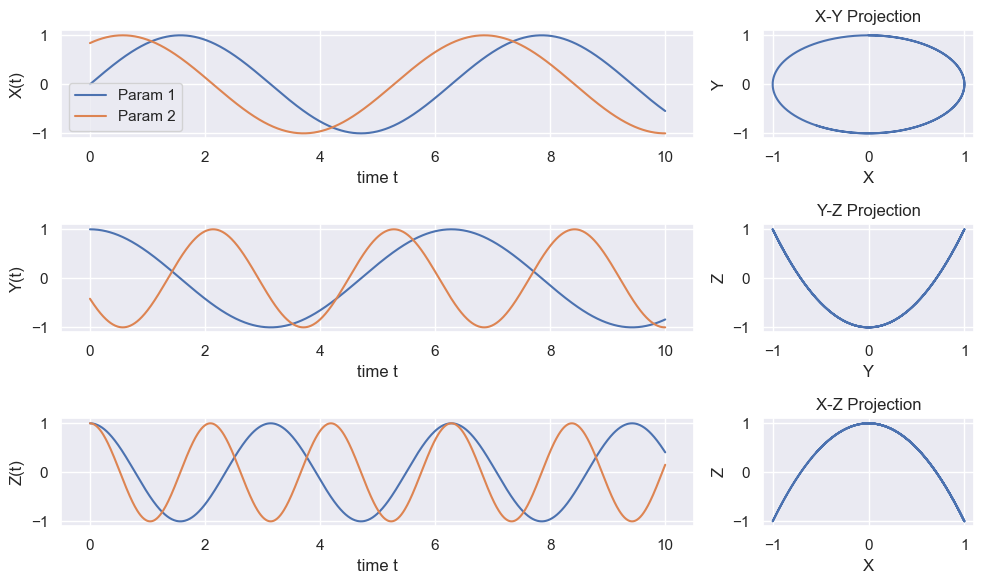

In [81]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)


# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{dy_0}{dt} &= y_1 \\
\frac{dy_1}{dt} &= -\frac{g}{l}\sin(y_0)
\end{align}

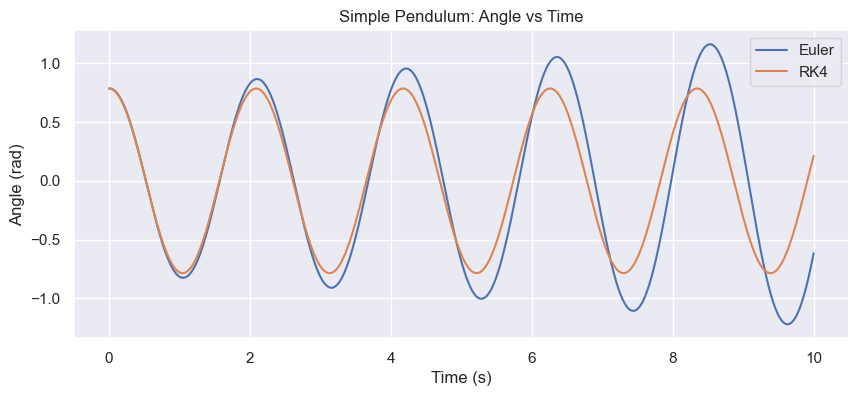

In [82]:
def pendulum_ode(t, Y):
    g = 9.81
    l = 1.0
    theta, omega = Y
    return np.array([omega, -(g/l)*np.sin(theta)])

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = [np.pi/4, 0.0]
t, Y_euler = euler(pendulum_ode, 0, 10, 1000, yinit)
t, Y_rk4 = rk4(pendulum_ode, 0, 10, 1000, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()